In [1]:
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\kraus\Desktop\Ironhack\amz_uk_price_prediction_dataset.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
bestseller_rate = df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)
bestseller_rate.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: isBestSeller, dtype: float64

In [6]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

chi2_stat, chi2_p, _, _ = chi2_contingency(crosstab_result)
cramers_v = association(crosstab_result, method="cramer")

print(chi2_p, cramers_v)

0.0 0.1222829439760564


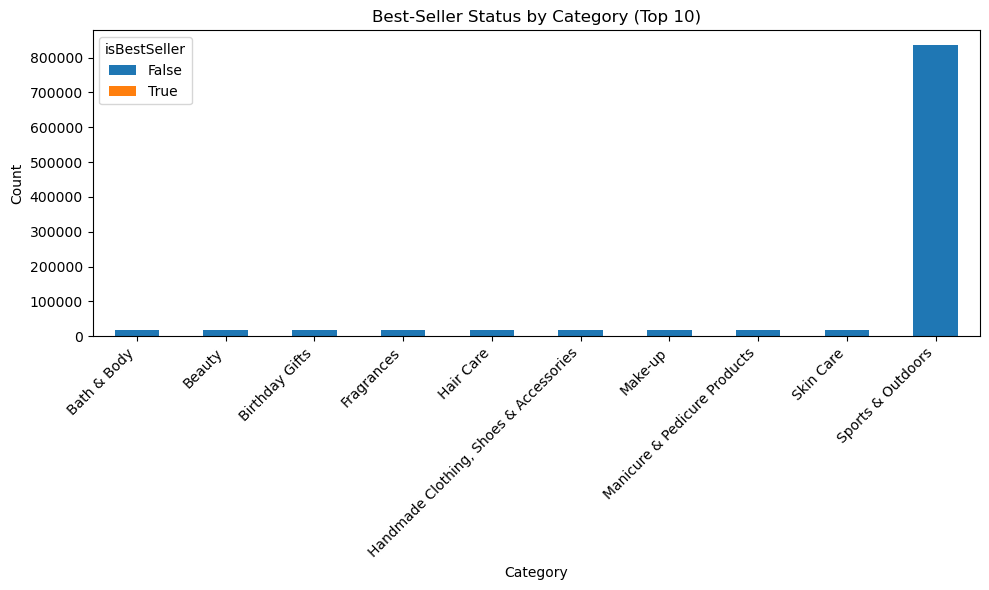

In [7]:
top_categories = df['category'].value_counts().head(10).index
subset = df[df['category'].isin(top_categories)]

crosstab_subset = pd.crosstab(subset['category'], subset['isBestSeller'])
crosstab_subset.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title('Best-Seller Status by Category (Top 10)')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [8]:
crosstab_subset

isBestSeller,False,True
category,,
Bath & Body,19059,33
Beauty,19010,302
Birthday Gifts,18943,35
Fragrances,18550,14
Hair Care,18665,70
"Handmade Clothing, Shoes & Accessories",19215,14
Make-up,18715,41
Manicure & Pedicure Products,18882,58
Skin Care,18711,58


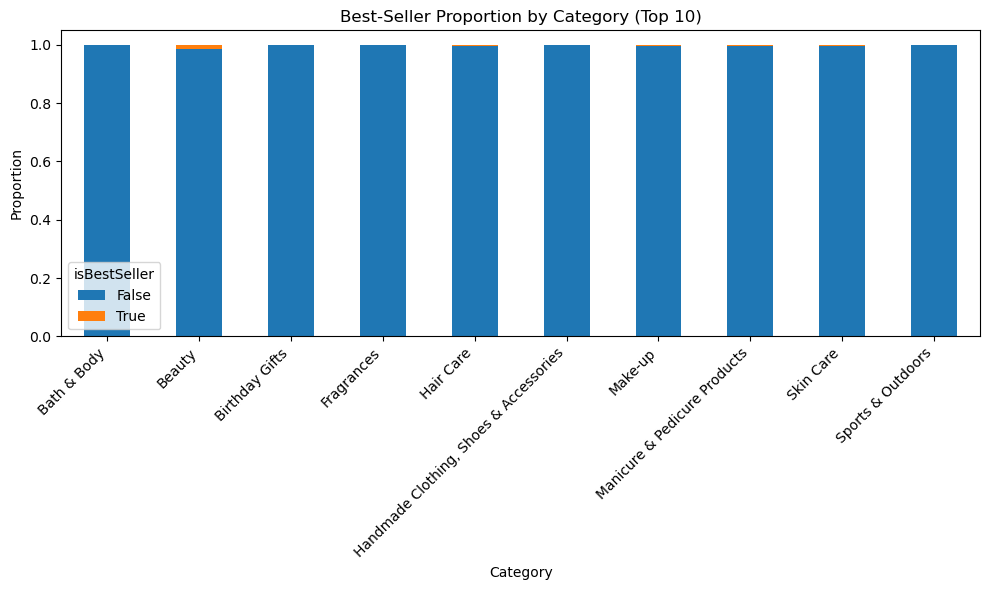

In [9]:
crosstab_pct = crosstab_subset.div(crosstab_subset.sum(axis=1), axis=0)
crosstab_pct.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title('Best-Seller Proportion by Category (Top 10)')
plt.xlabel('Category')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [10]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    return outliers

In [11]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original rows: {len(df)}, After removing outliers: {len(df_clean)}")

Original rows: 2443651, After removing outliers: 2115963


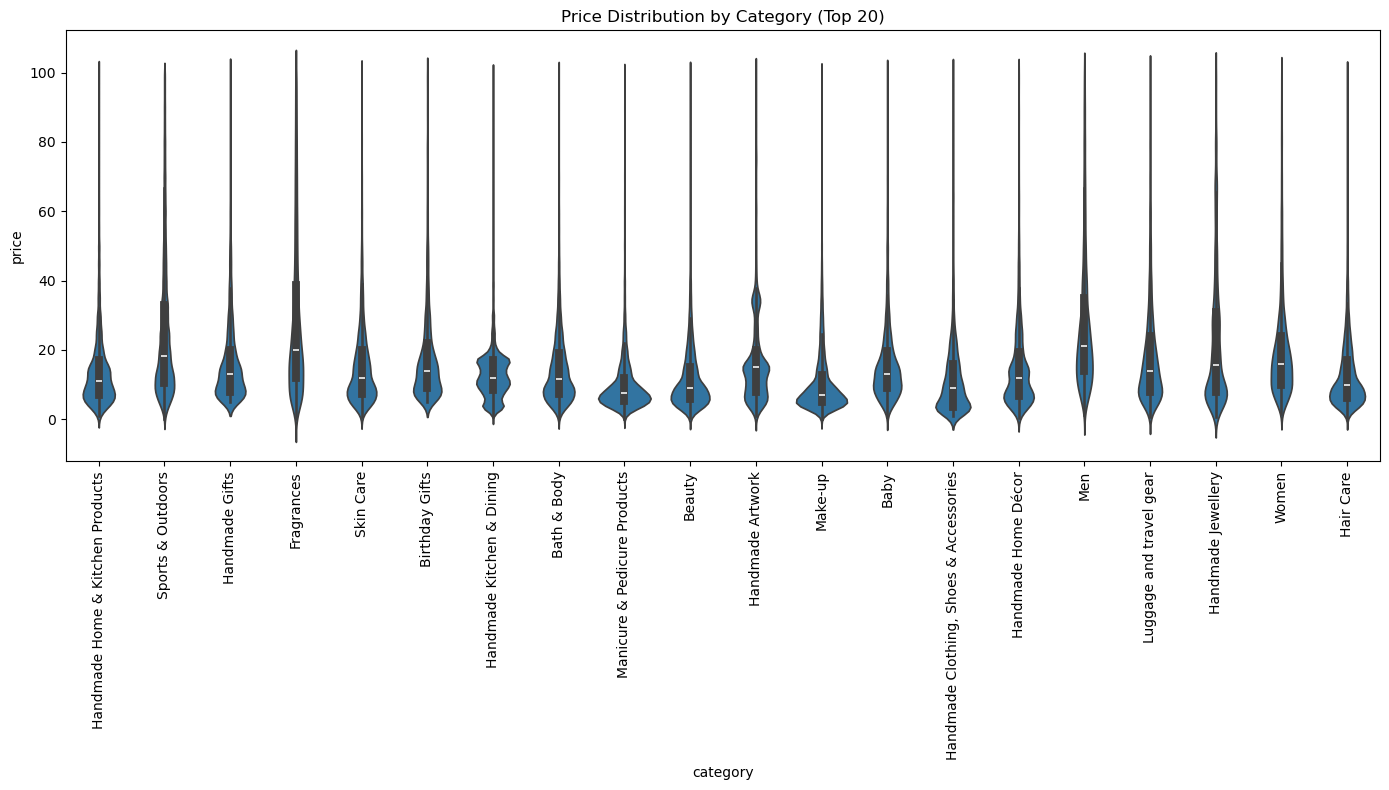

In [12]:
top20 = df_clean['category'].value_counts().head(20).index
subset = df_clean[df_clean['category'].isin(top20)]

plt.figure(figsize=(14,8))
sns.violinplot(data=subset, x='category', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Category (Top 20)')
plt.tight_layout()
plt.show()

In [13]:
median_by_category = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
median_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

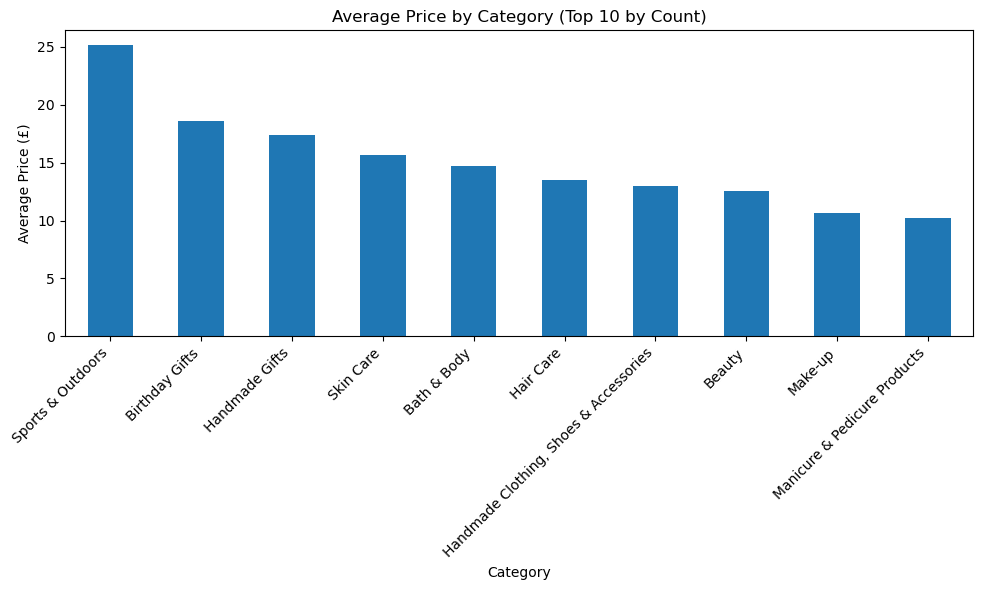

In [14]:
top10 = df_clean['category'].value_counts().head(10).index
subset10 = df_clean[df_clean['category'].isin(top10)]

avg_price = subset10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
avg_price.plot(kind='bar')
plt.title('Average Price by Category (Top 10 by Count)')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
avg_price

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

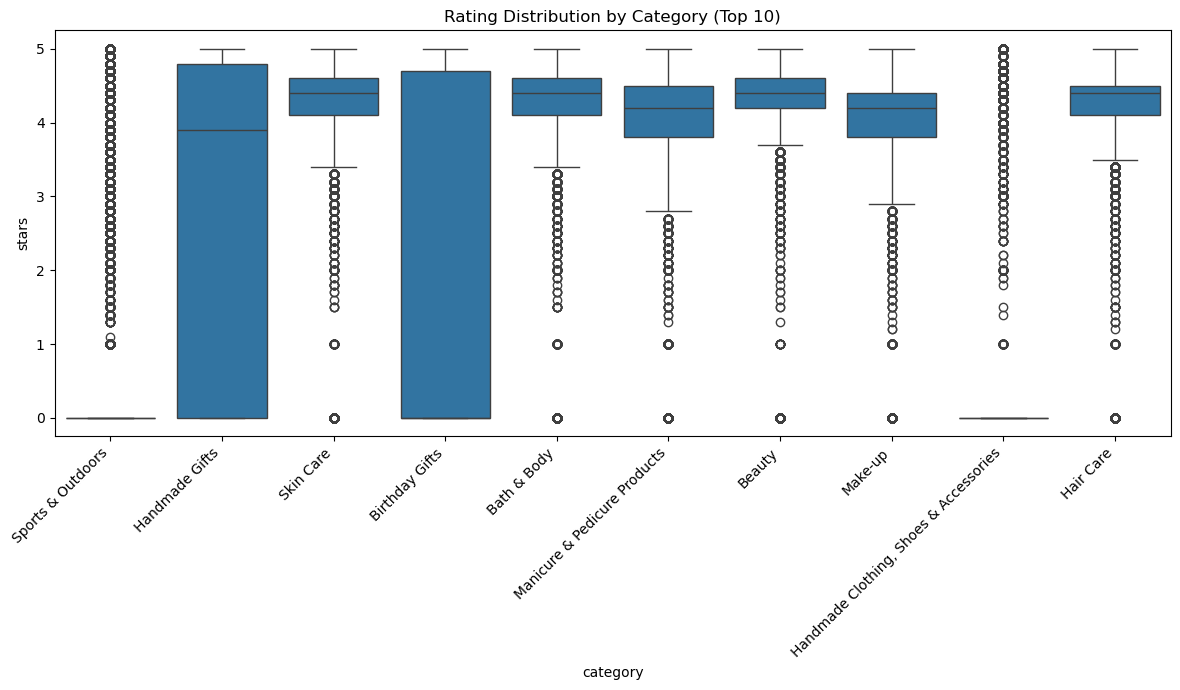

In [16]:
top10 = df_clean['category'].value_counts().head(10).index
subset10 = df_clean[df_clean['category'].isin(top10)]

plt.figure(figsize=(12,7))
sns.boxplot(data=subset10, x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.title('Rating Distribution by Category (Top 10)')
plt.tight_layout()
plt.show()

In [17]:
zero_rate_by_category = df_clean[df_clean['category'].isin(top10)].groupby('category').apply(lambda x: (x['stars'] == 0).mean())
zero_rate_by_category.sort_values(ascending=False)

C:\Users\kraus\AppData\Local\Temp\ipykernel_52968\4276296205.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zero_rate_by_category = df_clean[df_clean['category'].isin(top10)].groupby('category').apply(lambda x: (x['stars'] == 0).mean())


category
Sports & Outdoors                         0.817655
Handmade Clothing, Shoes & Accessories    0.764553
Birthday Gifts                            0.571964
Handmade Gifts                            0.450022
Manicure & Pedicure Products              0.110294
Bath & Body                               0.086089
Make-up                                   0.085105
Skin Care                                 0.043241
Hair Care                                 0.032054
Beauty                                    0.009879
dtype: float64

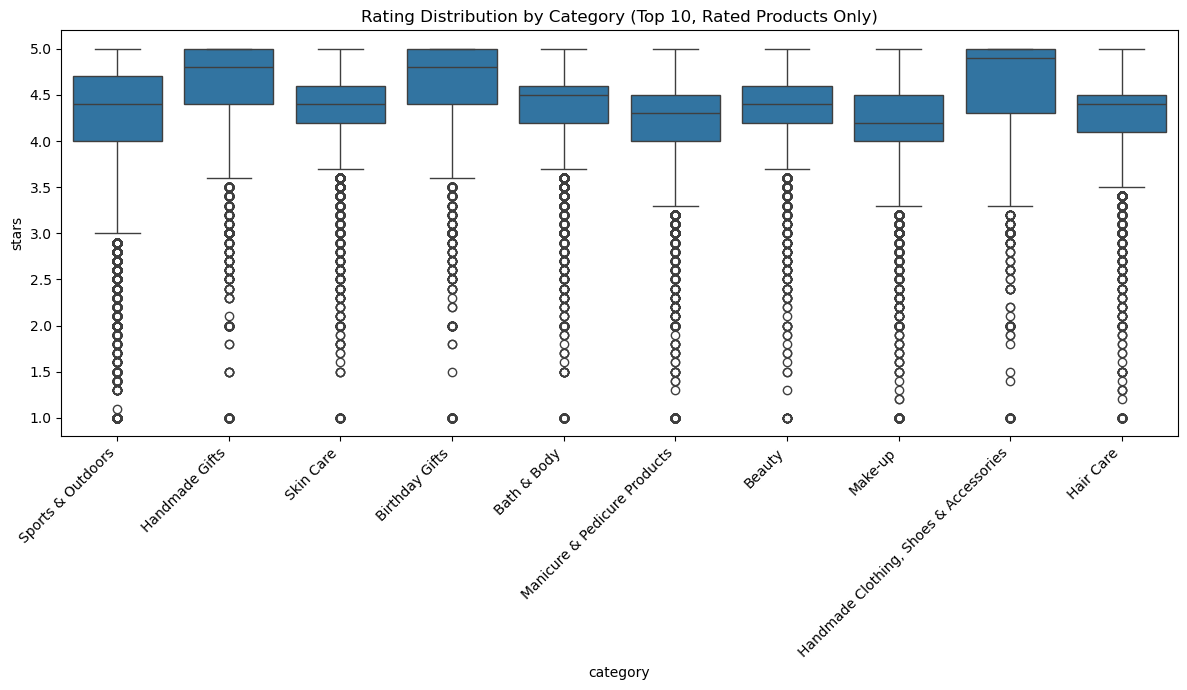

In [18]:
rated_only = df_clean[df_clean['stars'] > 0]
subset10_rated = rated_only[rated_only['category'].isin(top10)]

plt.figure(figsize=(12,7))
sns.boxplot(data=subset10_rated, x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.title('Rating Distribution by Category (Top 10, Rated Products Only)')
plt.tight_layout()
plt.show()

In [19]:
subset10_rated.groupby('category')['stars'].median().sort_values(ascending=False)

category
Handmade Clothing, Shoes & Accessories    4.9
Birthday Gifts                            4.8
Handmade Gifts                            4.8
Bath & Body                               4.5
Beauty                                    4.4
Hair Care                                 4.4
Skin Care                                 4.4
Sports & Outdoors                         4.4
Manicure & Pedicure Products              4.3
Make-up                                   4.2
Name: stars, dtype: float64

In [20]:
pearson_corr = df_clean[df_clean['stars'] > 0]['price'].corr(df_clean[df_clean['stars'] > 0]['stars'], method='pearson')
spearman_corr = df_clean[df_clean['stars'] > 0]['price'].corr(df_clean[df_clean['stars'] > 0]['stars'], method='spearman')

print(pearson_corr, spearman_corr)

0.00674450806715802 0.024659617205380444


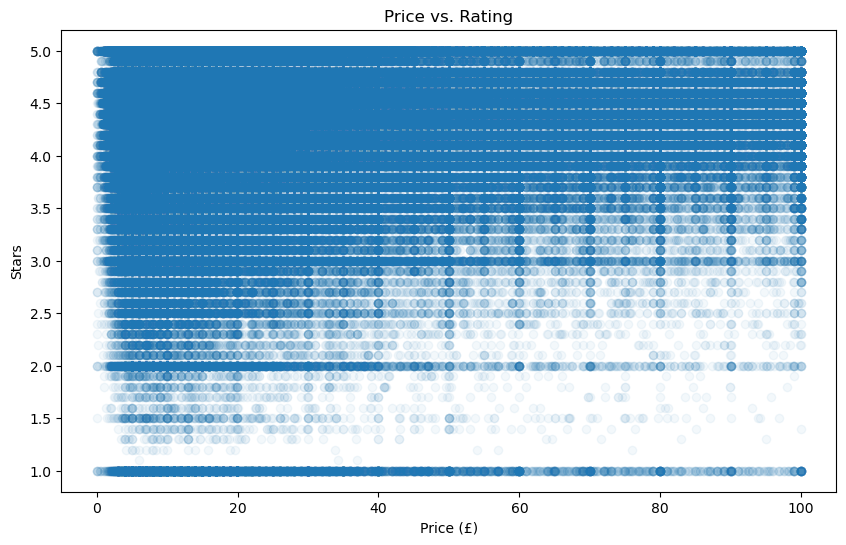

In [21]:
plt.figure(figsize=(10,6))
plt.scatter(df_clean[df_clean['stars'] > 0]['price'], df_clean[df_clean['stars'] > 0]['stars'], alpha=0.05)
plt.title('Price vs. Rating')
plt.xlabel('Price (£)')
plt.ylabel('Stars')
plt.show()

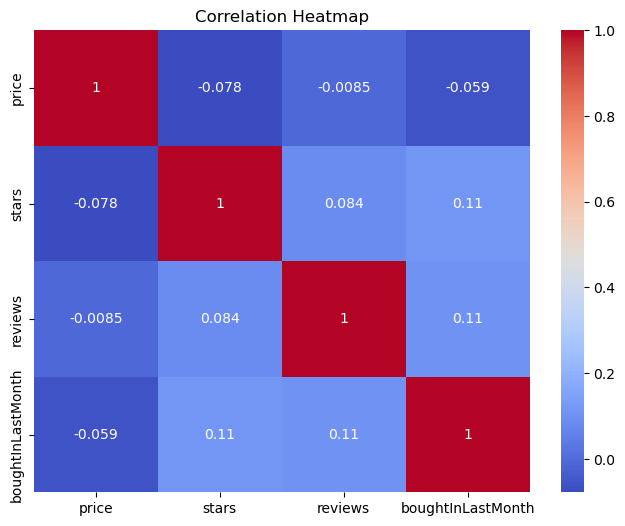

In [22]:
numerical_cols = df_clean[['price', 'stars', 'reviews', 'boughtInLastMonth']]
corr_matrix = numerical_cols.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

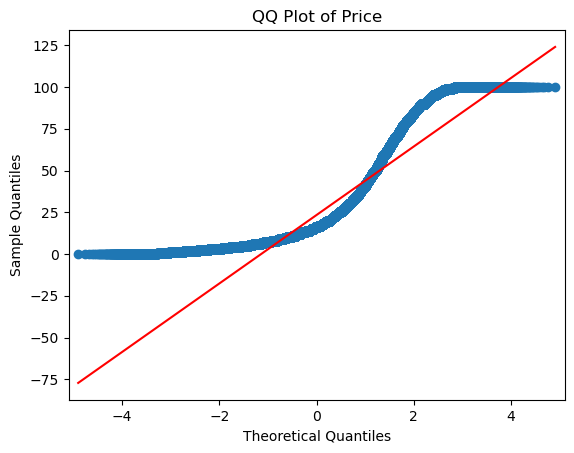

In [23]:
import statsmodels.api as sm

sm.qqplot(df_clean['price'], line='s')
plt.title('QQ Plot of Price')
plt.show()

In [ ]:
# Executive Summary — Amazon UK Product Insights (Bivariate Analysis)

# 1. Category vs. Bestseller Status
# Statistically significant but weak association.
# Category alone is a poor predictor of bestseller status, other factors likely dominate.

# 2. Volume vs. Price by Category
# Sports & Outdoors dominates by listing volume but is NOT the
# highest-priced category overall, that's tech hardware.
# Within top-10 most-listed categories, Sports & Outdoors does have the highest avg price.
# Takeaway: volume leaders and value leaders are different category segments.

# 3. Ratings Data Quality Issue
# 50% of products have stars = 0, likely representing "unrated" not "0-star."
# Zero-rate varies wildly by category: <1% (Beauty) to >80% (Sports & Outdoors).
# After filtering zeros, ratings are strongly left-skewed, clustered at 4.3-4.9 (normal reviewer behavior).
# Action: always filter stars > 0 before analysis.

# 4. Price Has No Meaningful Correlation with Rating, Reviews, or Recent Purchases
# All pairwise correlations (Pearson, Spearman, heatmap) were weak.
# Price does not predict customer satisfaction or purchase recency.

# 5. Outliers
# Tukey's IQR method flagged listings as price outliers.
# High proportion reflects genuine right-skew (likely a real premium segment), not data errors.